## TUGAS 2 SBP Tugas 2.xlsx

In [1]:
# lib data manipulations
import numpy as np
import pandas as pd

# lib data visualizaton
import seaborn as sns
import matplotlib.pyplot as plt

# lib data preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# lib supervised learning
from sklearn.tree import DecisionTreeClassifier, plot_tree

# library evaluation model
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## LOAD DATASET

In [2]:
# read file
df = pd.read_excel("Tugas 2.xlsx")

# tampilkan 5 baris pertama
df.head()

,No.,Mhs,Minat,Asal Pendidikan,Gender,Hobi,Hasil
0,1,A,Hardwere,SMK Komputer,L,Non IT,TI
1,2,B,Hardwere,SMK Komputer,L,IT,TI
2,3,C,Umum,SMK Komputer,L,Non IT,SI
3,4,D,Softwere,SMA Umum,L,Non IT,SI
4,5,E,Softwere,SMK Teknik,P,Non IT,SI


In [3]:
# bacic info
df.info()

# rows and column
print("",df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   No.              14 non-null     int64 
 1   Mhs              14 non-null     object
 2   Minat            14 non-null     object
 3   Asal Pendidikan  14 non-null     object
 4   Gender           14 non-null     object
 5   Hobi             14 non-null     object
 6   Hasil            14 non-null     object
dtypes: int64(1), object(6)
memory usage: 916.0+ bytes
 (14, 7)


## SPLIT DATA

In [5]:
# copy data
df_encoded = df.copy()

#initialization label encoder
le = LabelEncoder()

# change string to number
for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col])

# checking encoding
print(df_encoded.head())

   No.  Mhs  Minat  Asal Pendidikan  Gender  Hobi  Hasil
0    1    0      0                1       0     1      1
1    2    1      0                1       0     0      1
2    3    2      3                1       0     1      0
3    4    3      1                0       0     1      0
4    5    4      1                2       1     1      0


In [6]:
# split fitures (x) and label (y)
x = df_encoded[["Mhs", "Minat", "Asal Pendidikan", "Gender", "Hobi"]]
y = df_encoded["Hasil"]

In [7]:
# split validation
trainX, testX, trainY, testY = train_test_split(
  x, y, train_size=0.7, test_size=0.3, random_state=7, shuffle=True
)

## MODELING SUPERVISED LEARNING

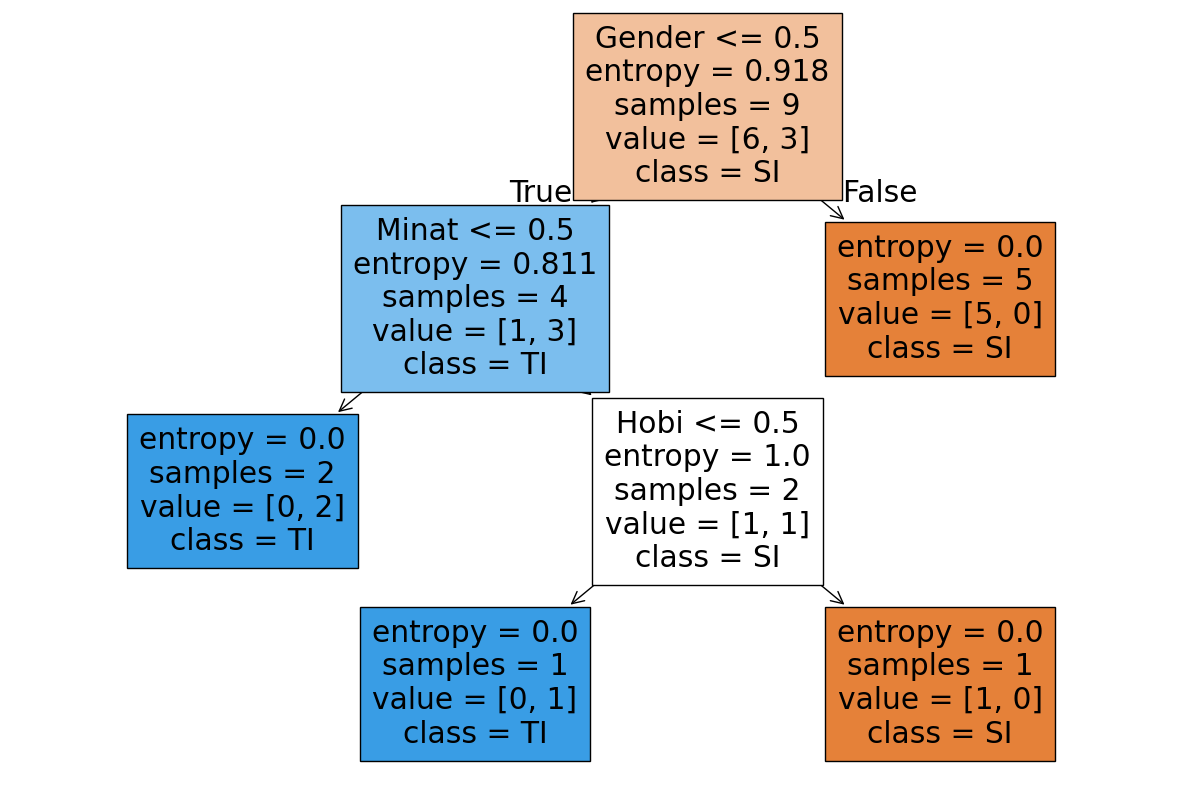

In [13]:
# supervised learning algorithm
model = DecisionTreeClassifier(criterion="entropy", random_state=42)
model.fit(trainX, trainY)

# show decision tree
plt.figure(figsize=(15, 10))
plot_tree(model, feature_names=x.columns, class_names=["SI", "TI"], filled=True)
plt.show()

In [9]:
# evaluation models - confusion_matrix
Ypred = model.predict(testX)

## SET CONFUSION MATRIX

In [10]:
# confusion matrix
cm = confusion_matrix(testY, Ypred)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[3 1]
 [0 1]]


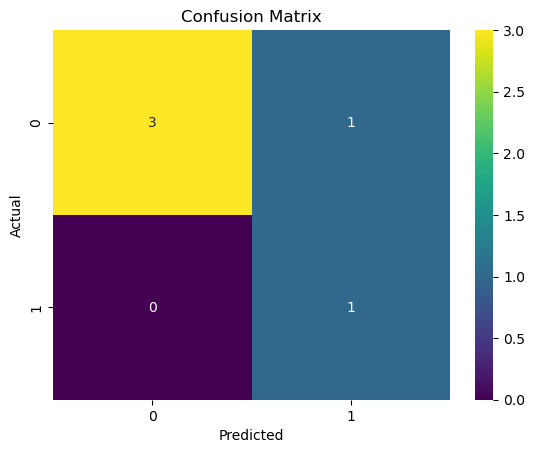

In [11]:
# visualization confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="viridis")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [12]:
# evaluation models - classification_report
print(classification_report(testY, Ypred))

# accuracy
acc = accuracy_score(testY, Ypred)
print("Accuracy:", acc)

              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.50      1.00      0.67         1

    accuracy                           0.80         5
   macro avg       0.75      0.88      0.76         5
weighted avg       0.90      0.80      0.82         5

Accuracy: 0.8
